Grab the relevant columns

In [ ]:
import pandas as pd

# Load the Excel file into a Pandas DataFrame
try:
    # df = pd.read_csv('/content/quikfix.csv') # i removed row number 618 and it fixed it
    df = pd.read_csv('../../data/predictions/llm/raw/gemini_2step_script2values.csv', on_bad_lines='warn', sep=',') # skip bad lines, and explicitly set the separator
except FileNotFoundError:
    print("Error: File not found. Please make sure the file path is correct.")
    df = pd.DataFrame()  # Create an empty DataFrame to avoid further errors
if 'filename' in df.columns:
    df = df.rename(columns={'filename': '1_Link1'})
# Specify the desired columns
selected_columns = [
    '1_Link1',
    '1_Value1_Self_Direction_Thought_values',
    '1_Value1_Self_Direction_Action_values',
    '1_Value1_Stimulation_values',
    '1_Value1_Hedonism_values',
    '1_Value1_Achievement_values',
    '1_Value1_Power_Resources_values',
    '1_Value1_Power_dominance_values',
    '1_Value1_Face_values',
    '1_Value1_Security_Personal_values',
    '1_Value1_Security_Social_values',
    '1_Value1_Conformity_Rules_values',
    '1_Value1_Conformity_Interpersonal_values',
    '1_Value1_Tradition_values',
    '1_Value1_Humility_values',
    '1_Value1_Benevolence_Dependability_values',
    '1_Value1_Benevolence_Care_values',
    '1_Value1_Universalism_Concern_values',
    '1_Value1_Universalism_Nature_values',
    '1_Value1_Universalism_Tolerance_values'
]

# Create a new DataFrame with only the selected columns
if not df.empty:
    pred_df = df[selected_columns]
    # print(values_df)
else:
    print("DataFrame is empty. Cannot create a new DataFrame with selected columns.")

Error: File not found. Please make sure the file path is correct.
DataFrame is empty. Cannot create a new DataFrame with selected columns.


In [ ]:
pred_df

,1_Link1,1_Value1_Self_Direction_Thought_values,1_Value1_Self_Direction_Action_values,1_Value1_Stimulation_values,1_Value1_Hedonism_values,1_Value1_Achievement_values,1_Value1_Power_Resources_values,1_Value1_Power_dominance_values,1_Value1_Face_values,1_Value1_Security_Personal_values,1_Value1_Security_Social_values,1_Value1_Conformity_Rules_values,1_Value1_Conformity_Interpersonal_values,1_Value1_Tradition_values,1_Value1_Humility_values,1_Value1_Benevolence_Dependability_values,1_Value1_Benevolence_Care_values,1_Value1_Universalism_Concern_values,1_Value1_Universalism_Nature_values,1_Value1_Universalism_Tolerance_values
0,@alexkay_video_6783398367490854150,NaN,conflict,NaN,NaN,NaN,conflict,NaN,present,conflict,conflict,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,@alexkay_video_6807140917636648197,NaN,NaN,NaN,present,NaN,NaN,present,present,present,NaN,NaN,NaN,NaN,conflict,conflict,NaN,NaN,NaN,NaN
2,@alexkay_video_6811970678024195334,present,present,present,present,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,@alexkay_video_6905879944979631365,NaN,NaN,NaN,present,NaN,present,NaN,NaN,present,NaN,NaN,NaN,present,NaN,NaN,present,NaN,NaN,NaN
4,@alexkay_video_6925220555478027525,NaN,NaN,NaN,present,present,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,@zeuz__video_7346995193024957727,NaN,present,present,present,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1043,@zeuz__video_7347384674781646111,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1044,@zeuz__video_7347848700145700126,NaN,present,NaN,NaN,present,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1045,@zeuz__video_7348138821680139551,NaN,present,present,present,present,present,present,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Look for dirty data to clean

In [ ]:
for column in pred_df.columns:
    if column=='1_Link1':
        continue
    print(f"Column: {column}")
    print(pred_df[column].unique())
    print("-" * 20)

Column: 1_Value1_Self_Direction_Thought_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Self_Direction_Action_values
['conflict' nan 'present' '-1' '1']
--------------------
Column: 1_Value1_Stimulation_values
[nan 'present' 'conflict' '1' "{'present': 1}"]
--------------------
Column: 1_Value1_Hedonism_values
[nan 'present' 'conflict' '1' "{'present': 1}"]
--------------------
Column: 1_Value1_Achievement_values
[nan 'present' 'conflict' '-1']
--------------------
Column: 1_Value1_Power_Resources_values
['conflict' nan 'present']
--------------------
Column: 1_Value1_Power_dominance_values
[nan 'present' 'conflict' '-1']
--------------------
Column: 1_Value1_Face_values
['present' nan 'conflict' '1' '-1' "{'present': 1}"]
--------------------
Column: 1_Value1_Security_Personal_values
['conflict' 'present' nan '2' "{'present': 1}"]
--------------------
Column: 1_Value1_Security_Social_values
['conflict' nan 'present']
--------------------
Column: 1_Value1_Confor

In [ ]:
import numpy as np

def clean_values_dataframe(values_df):
    """
    Cleans the specified DataFrame by replacing invalid or inconsistent values
    in columns ending with '_values' or '_channel'.

    Args:
        values_df (pd.DataFrame): The DataFrame to clean.

    Returns:
        pd.DataFrame: The cleaned DataFrame.
    """
    # Define allowed values for different column types
    values_allowed_values = {'present', 'dominant', 'conflict', None}
    channel_allowed_values = {'verbal', 'visual', 'both', np.nan}

    for col in values_df.columns:
        if col.endswith('_values'):
            # Replace specific invalid values with None
            values_df[col] = values_df[col].replace([' None', 'none', ' ', '\xa0','0', "{'present': 0, 'conflict': 0, 'None': 1}", "{'present': 0, 'conflict': 0, 'dominant': 0}"], np.nan)
            # Normalize specific values
            values_df[col] = values_df[col].replace(["'present'",'present ','1', 'pres', 'verbal',"{'present': 1}","{'present': 2, 'conflict': 0, 'None': 0}", "{'present': 2, 'conflict': 0, 'dominant': 0}"], 'present')
            values_df[col] = values_df[col].replace(["{'present': 0, 'conflict': -1, 'None': 0}", 'c', 'confict','-1', "{'conflict': -1}", "{'present': 0, 'conflict': -1, 'dominant': 0}"], 'conflict')
            values_df[col] = values_df[col].replace(['d', 'dominant','2', "{'present': 2}", "{'present': 2, 'conflict': 0, 'None': 0}"], 'dominant')

        elif col.endswith('_channel'):
            # Replace specific invalid values with None
            values_df[col] = values_df[col].replace(['none', ' ', '\xa0', "{'present': 0, 'conflict': 0, 'None': 1}"], np.nan)
            # Normalize specific values
            values_df[col] = values_df[col].replace(['ver', 'verbal ', 'v'], 'verbal')
            values_df[col] = values_df[col].replace(['b', 'both '], 'both')
            values_df[col] = values_df[col].replace(['c', 'confict'], 'conflict')

    return values_df


In [ ]:
for column in pred_df.columns:
    if column=='1_Link1':
        continue
    print(f"Column: {column}")
    print(pred_df[column].unique())
    print("-" * 20)

Column: 1_Value1_Self_Direction_Thought_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Self_Direction_Action_values
['conflict' nan 'present' '-1' '1']
--------------------
Column: 1_Value1_Stimulation_values
[nan 'present' 'conflict' '1' "{'present': 1}"]
--------------------
Column: 1_Value1_Hedonism_values
[nan 'present' 'conflict' '1' "{'present': 1}"]
--------------------
Column: 1_Value1_Achievement_values
[nan 'present' 'conflict' '-1']
--------------------
Column: 1_Value1_Power_Resources_values
['conflict' nan 'present']
--------------------
Column: 1_Value1_Power_dominance_values
[nan 'present' 'conflict' '-1']
--------------------
Column: 1_Value1_Face_values
['present' nan 'conflict' '1' '-1' "{'present': 1}"]
--------------------
Column: 1_Value1_Security_Personal_values
['conflict' 'present' nan '2' "{'present': 1}"]
--------------------
Column: 1_Value1_Security_Social_values
['conflict' nan 'present']
--------------------
Column: 1_Value1_Confor

In [ ]:
pred_df = clean_values_dataframe(pred_df)

<ipython-input-4-899b3d54722b>:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  values_df[col] = values_df[col].replace([' None', 'none', ' ', '\xa0','0', "{'present': 0, 'conflict': 0, 'None': 1}", "{'present': 0, 'conflict': 0, 'dominant': 0}"], np.nan)
<ipython-input-4-899b3d54722b>:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  values_df[col] = values_df[col].replace(["'present'",'present ','1', 'pres', 'verbal',"{'present': 1}","{'present': 2, 'conflict': 0, 'None': 0}", "{'present': 2, 'conflict':

In [ ]:

pred_df.to_csv('cleaned_video_predictions.csv', index=False)

Start comparing

In [ ]:
import pandas as pd

# Load the ground truth and prediction data
ground_truth = pd.read_csv('../../data/annotations/ground_truth_labels.csv')
predictions = pd.read_csv('cleaned_video_predictions.csv')
# Rename the 'filename' column in the predictions DataFrame
if 'filename' in predictions.columns:
    predictions = predictions.rename(columns={'filename': '1_Link1'})


# ground_truth['1_Link1'] = ground_truth['1_Link1'].str.extract(r'@([^/]+)/video/(\d+)').apply(lambda x: f"@{x[0]}_video_{x[1]}", axis=1)

# Filter ground truth based on '1_Link1' column
# ground_truth = ground_truth[ground_truth['1_Link1'].isin(predictions['1_Link1'])]
predictions = predictions[predictions['1_Link1'].isin(ground_truth['1_Link1'])]

# Ensure both dataframes have the same number of rows and order
ground_truth = ground_truth.sort_values(by=['1_Link1']).reset_index(drop=True)
predictions = predictions.sort_values(by=['1_Link1']).reset_index(drop=True)

In [ ]:
ground_truth

,1_Link1,1_Value1_Self_Direction_Thought_values,1_Value1_Self_Direction_Action_values,1_Value1_Stimulation_values,1_Value1_Hedonism_values,1_Value1_Achievement_values,1_Value1_Power_Resources_values,1_Value1_Power_dominance_values,1_Value1_Face_values,1_Value1_Security_Personal_values,1_Value1_Security_Social_values,1_Value1_Conformity_Rules_values,1_Value1_Conformity_Interpersonal_values,1_Value1_Tradition_values,1_Value1_Humility_values,1_Value1_Benevolence_Dependability_values,1_Value1_Benevolence_Care_values,1_Value1_Universalism_Concern_values,1_Value1_Universalism_Nature_values,1_Value1_Universalism_Tolerance_values
0,@alexkay_video_6783398367490854150,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN
1,@alexkay_video_6807140917636648197,NaN,conflict,NaN,NaN,present,NaN,conflict,present,conflict,NaN,NaN,present,NaN,conflict,NaN,conflict,NaN,NaN,NaN
2,@alexkay_video_6811970678024195334,NaN,present,present,NaN,NaN,NaN,dominant,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,present,NaN,NaN,NaN
3,@alexkay_video_6905879944979631365,NaN,NaN,NaN,NaN,NaN,dominant,NaN,NaN,NaN,NaN,NaN,conflict,present,NaN,NaN,present,NaN,NaN,NaN
4,@alexkay_video_6925220555478027525,NaN,present,NaN,NaN,dominant,present,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,@zeuz__video_7346995193024957727,present,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN
886,@zeuz__video_7347384674781646111,NaN,NaN,NaN,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,conflict,NaN,NaN,NaN
887,@zeuz__video_7347848700145700126,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,present,NaN,present,NaN,NaN,NaN
888,@zeuz__video_7348138821680139551,NaN,NaN,NaN,NaN,present,NaN,dominant,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
for column in predictions.columns:
    print(f"Column: {column}")
    print(predictions[column].unique())
    print("-" * 20)

Column: 1_Link1
['@alexkay_video_6783398367490854150' '@alexkay_video_6807140917636648197'
 '@alexkay_video_6811970678024195334' '@alexkay_video_6905879944979631365'
 '@alexkay_video_6925220555478027525' '@alexkay_video_6986669243156745478'
 '@alexkay_video_6998241581232917766' '@alexkay_video_7014141317097852165'
 '@alexkay_video_7202015966824353067' '@alexkay_video_7325114085752737070'
 '@alia_video_7334789206327217441' '@alia_video_7336234980273573152'
 '@alia_video_7337388501555563808' '@alia_video_7338157060443393313'
 '@alia_video_7339254414043073825' '@alia_video_7341060279108717857'
 '@alia_video_7342164619835788576' '@alia_video_7343979963453836576'
 '@alia_video_7345563238207376673' '@alia_video_7346300665020370209'
 '@ameliezilber_video_7301412529778068779'
 '@ameliezilber_video_7306218804399394091'
 '@ameliezilber_video_7308089561199201582'
 '@ameliezilber_video_7311806912817843499'
 '@ameliezilber_video_7312963030734687531'
 '@ameliezilber_video_7314832924895907118'
 '@ame

In [ ]:

selected_columns = [
    '1_Link1',
    '1_Value1_Self_Direction_Thought_values',
    '1_Value1_Self_Direction_Action_values',
    '1_Value1_Stimulation_values',
    '1_Value1_Hedonism_values',
    '1_Value1_Achievement_values',
    '1_Value1_Power_Resources_values',
    '1_Value1_Power_dominance_values',
    '1_Value1_Face_values',
    '1_Value1_Security_Personal_values',
    '1_Value1_Security_Social_values',
    '1_Value1_Conformity_Rules_values',
    '1_Value1_Conformity_Interpersonal_values',
    '1_Value1_Tradition_values',
    '1_Value1_Humility_values',
    '1_Value1_Benevolence_Dependability_values',
    '1_Value1_Benevolence_Care_values',
    '1_Value1_Universalism_Concern_values',
    '1_Value1_Universalism_Nature_values',
    '1_Value1_Universalism_Tolerance_values'
]

# Create a new DataFrame with only the selected columns
ground_truth = ground_truth[selected_columns]
predictions = predictions[selected_columns]


In [ ]:
# turn the values to vectors by different resolutions
import pandas as pd
import numpy as np

# Define the function
def transform_values(df, resolution_score):
    # Define the mappings
    mappings = {
        'high': {'present': 1, np.nan: 0, 'dominant': 2, 'conflict': -1},
        'mid': {'present': 1, np.nan: 0, 'dominant': 1, 'conflict': -1},
        'low': {'present': 1, np.nan: 0, 'dominant': 1, 'conflict': 1}
    }

    # Ensure the resolution_score is valid
    if resolution_score not in mappings:
        raise ValueError("Invalid resolution score. Choose 'high', 'mid', or 'low'.")

    # Map values based on the resolution score
    df_transformed = df.replace(mappings[resolution_score])
    return df_transformed

resolution = 'mid'
ground_truth_transformed = transform_values(ground_truth, resolution)
predictions_transformed = transform_values(predictions, resolution)


<ipython-input-16-2f7e5a4609c5>:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_transformed = df.replace(mappings[resolution_score])


In [ ]:
import pandas as pd

def split_multilabels(df, label_columns):
    """
    Splits a DataFrame with {1, -1, 0} labels into two DataFrames:
    - One with binary labels {0, 1}
    - One with binary labels {0, 1}, where -1 is converted to 1

    Args:
        df (pd.DataFrame): Input DataFrame containing the labels.
        label_columns (list): List of column names with the labels to process.

    Returns:
        tuple: (df_01, df_0neg1), where
            - df_01 contains binary labels {0, 1}
            - df_0neg1 contains binary labels {0, 1} (converted from {0, -1})
    """
    # Copy the original DataFrame to preserve the input
    df_01 = df.copy()
    df_0neg1 = df.copy()

    # Process the {0, 1} DataFrame
    # Use applymap instead of map for element-wise operations on numerical data
    df_01[label_columns] = df_01[label_columns].applymap(lambda x: x if x in [0, 1] else 0)

    # Process the {0, 1} DataFrame from {0, -1}
    # Use applymap instead of map for element-wise operations on numerical data
    df_0neg1[label_columns] = df_0neg1[label_columns].applymap(lambda x: 1 if x == -1 else (x if x == 0 else 0))

    return df_01, df_0neg1

In [ ]:
predictions_pos, predictions_neg = split_multilabels(predictions_transformed, selected_columns[1:])
ground_truth_pos, ground_truth_neg = split_multilabels(ground_truth_transformed, selected_columns[1:])

<ipython-input-17-2f483626a696>:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_01[label_columns] = df_01[label_columns].applymap(lambda x: x if x in [0, 1] else 0)
<ipython-input-17-2f483626a696>:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_0neg1[label_columns] = df_0neg1[label_columns].applymap(lambda x: 1 if x == -1 else (x if x == 0 else 0))
<ipython-input-17-2f483626a696>:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_01[label_columns] = df_01[label_columns].applymap(lambda x: x if x in [0, 1] else 0)
<ipython-input-17-2f483626a696>:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_0neg1[label_columns] = df_0neg1[label_columns].applymap(lambda x: 1 if x == -1 else (x if x == 0 else 0))


In [ ]:
predictions_neg

,1_Link1,1_Value1_Self_Direction_Thought_values,1_Value1_Self_Direction_Action_values,1_Value1_Stimulation_values,1_Value1_Hedonism_values,1_Value1_Achievement_values,1_Value1_Power_Resources_values,1_Value1_Power_dominance_values,1_Value1_Face_values,1_Value1_Security_Personal_values,1_Value1_Security_Social_values,1_Value1_Conformity_Rules_values,1_Value1_Conformity_Interpersonal_values,1_Value1_Tradition_values,1_Value1_Humility_values,1_Value1_Benevolence_Dependability_values,1_Value1_Benevolence_Care_values,1_Value1_Universalism_Concern_values,1_Value1_Universalism_Nature_values,1_Value1_Universalism_Tolerance_values
0,@alexkay_video_6783398367490854150,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0.0,0
1,@alexkay_video_6807140917636648197,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0.0,0
2,@alexkay_video_6811970678024195334,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0.0,0
3,@alexkay_video_6905879944979631365,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0
4,@alexkay_video_6925220555478027525,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
880,@zeuz__video_7346995193024957727,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0
881,@zeuz__video_7347384674781646111,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0
882,@zeuz__video_7347848700145700126,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0.0,0
883,@zeuz__video_7348138821680139551,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0.0,0


Start with 12 values reduction

In [ ]:
value_mappings = {
        '1_Value1_Self_Direction_Thought_values': 'SDT',
        '1_Value1_Self_Direction_Action_values': 'SDA',
        '1_Value1_Stimulation_values': 'ST',
        '1_Value1_Hedonism_values': 'HE',
        '1_Value1_Achievement_values': 'AC',
        '1_Value1_Power_Resources_values': 'POR',
        '1_Value1_Power_dominance_values': 'POD',
        '1_Value1_Face_values': 'FA',
        '1_Value1_Security_Personal_values': 'SEP',
        '1_Value1_Security_Social_values': 'SES',
        '1_Value1_Conformity_Rules_values': 'COR',
        '1_Value1_Conformity_Interpersonal_values': 'COI',
        '1_Value1_Tradition_values': 'TR',
        '1_Value1_Humility_values': 'HU',
        '1_Value1_Benevolence_Dependability_values': 'BED',
        '1_Value1_Benevolence_Care_values': 'BEC',
        '1_Value1_Universalism_Concern_values': 'UNC',
        '1_Value1_Universalism_Nature_values': 'UNN',
        '1_Value1_Universalism_Tolerance_values': 'UT'
    }
value19To12 = {
        'SDT': 'SD',
        'SDA': 'SD',
        'ST': 'ST',
        'HE': 'HE',
        'AC': 'AC',
        'POR': 'PO',
        'POD': 'PO',
        'FA': 'FA',
        'SEP': 'SE',
        'SES': 'SE',
        'COR': 'CO',
        'COI': 'CO',
        'TR': 'TR',
        'HU': 'HU',
        'BED': 'BE',
        'BEC': 'BE',
        'UNC': 'UN',
        'UNN': 'UN',
        'UT': 'UN'
    }


In [ ]:
def reduce_columns(df, value_mappings, value19To12, link_column='1_Link1'):
    """
    Reduces columns in a DataFrame based on two mappings:
    1. value_mappings: Maps original column names to intermediate names.
    2. value19To12: Maps intermediate names to final reduced names.

    Args:
        df (pd.DataFrame): Input DataFrame with original column names.
        value_mappings (dict): Mapping of original column names to intermediate names.
        value19To12 (dict): Mapping of intermediate names to reduced names.
        link_column (str): Column name to ignore during processing.

    Returns:
        pd.DataFrame: Reduced DataFrame with the link column preserved.
    """
    # Preserve the link column
    reduced_df = df[[link_column]].copy() if link_column in df.columns else pd.DataFrame()

    # Filter out the link column from value_mappings
    value_mappings = {k: v for k, v in value_mappings.items() if k != link_column}

    # Step 1: Rename columns using value_mappings
    df = df.rename(columns=value_mappings)
    paradoxes = []
    # Step 2: Reduce columns according to value19To12
    for new_col in set(value19To12.values()):
        # Find all intermediate columns mapping to this new column
        cols_to_merge = [col for col, mapped in value19To12.items() if mapped == new_col]

        if len(cols_to_merge) == 1:
            # If one-to-one mapping
            col_name = cols_to_merge[0]
            # Check for non-numeric values
            non_numeric = df[col_name][~pd.to_numeric(df[col_name], errors='coerce').notna()]
            if not non_numeric.empty:
                print(f"Non-numeric values in column '{col_name}':")
                print(non_numeric)
            # Convert to numeric and fill NaN with 0
            reduced_df[new_col] = pd.to_numeric(df[col_name], errors='coerce').fillna(0)
        else:
            # If many-to-one mapping, handle summation
            cols_data = df[cols_to_merge].apply(pd.to_numeric, errors='coerce').fillna(0)
            # Go over every pair or triplet of rows and check for 1 and -1
            print(f"Checking for 1 and -1 in the rows for new column '{new_col}':")
            for index, row in cols_data.iterrows():
                if 1 in row.values and -1 in row.values:
                    print(f"Row index {index} contains both 1 and -1: {row.values}")
                    paradoxes.append(df.loc[[df.index[index]], [link_column]])
            reduced_df[new_col] = cols_data.sum(axis=1).clip(-1, 1)
    print(f"Found {len(paradoxes)} paradoxes:")
    print(paradoxes)
    return reduced_df, paradoxes


In [ ]:
predictions_pos_12_valued,_ = reduce_columns(predictions_pos, value_mappings, value19To12)
predictions_neg_12_valued,_ = reduce_columns(predictions_neg, value_mappings, value19To12)

ground_truth_pos_12_valued,_ = reduce_columns(ground_truth_pos, value_mappings, value19To12)
ground_truth_neg_12_valued,_ = reduce_columns(ground_truth_neg, value_mappings, value19To12)

Checking for 1 and -1 in the rows for new column 'PO':
Checking for 1 and -1 in the rows for new column 'CO':
Checking for 1 and -1 in the rows for new column 'SD':
Checking for 1 and -1 in the rows for new column 'SE':
Checking for 1 and -1 in the rows for new column 'BE':
Checking for 1 and -1 in the rows for new column 'UN':
Found 0 paradoxes:
[]
Checking for 1 and -1 in the rows for new column 'PO':
Checking for 1 and -1 in the rows for new column 'CO':
Checking for 1 and -1 in the rows for new column 'SD':
Checking for 1 and -1 in the rows for new column 'SE':
Checking for 1 and -1 in the rows for new column 'BE':
Checking for 1 and -1 in the rows for new column 'UN':
Found 0 paradoxes:
[]
Checking for 1 and -1 in the rows for new column 'PO':
Checking for 1 and -1 in the rows for new column 'CO':
Checking for 1 and -1 in the rows for new column 'SD':
Checking for 1 and -1 in the rows for new column 'SE':
Checking for 1 and -1 in the rows for new column 'BE':
Checking for 1 and -1

In [ ]:
import pandas as pd

def join_and_label(positive_df, negative_df):
    """
    Joins two DataFrames with positive and negative labels, keeping track of the label.

    Args:
        positive_df (pd.DataFrame): DataFrame with positive values.
        negative_df (pd.DataFrame): DataFrame with negative values.

    Returns:
        pd.DataFrame: Combined DataFrame with positive and negative labels tracked.
    """
    # Rename columns to include suffixes to differentiate positive and negative
    positive_df = positive_df.rename(columns={col: f"{col}_positive" for col in positive_df.columns if col != '1_Link1'})
    negative_df = negative_df.rename(columns={col: f"{col}_negative" for col in negative_df.columns if col != '1_Link1'})

    # Join both DataFrames on the '1_Link1' column
    combined_df = pd.merge(positive_df, negative_df, on='1_Link1', how='outer')

    return combined_df



In [ ]:
# combine the dfs
combined_ground_truth_12_values = join_and_label(ground_truth_pos_12_valued, ground_truth_neg_12_valued)
combined_predictions_12_values = join_and_label(predictions_pos_12_valued, predictions_neg_12_valued)

# save to csv
combined_ground_truth_12_values.to_csv('combined_ground_truth_12_values.csv', index=False)
combined_predictions_12_values.to_csv('combined_predictions_12_values.csv', index=False)


In [ ]:
for column in combined_ground_truth_12_values.columns:
    print(f"Column: {column}")
    print(combined_ground_truth_12_values[column].unique())
    print("-" * 20)

Column: 1_Link1
['@alexkay_video_6783398367490854150' '@alexkay_video_6807140917636648197'
 '@alexkay_video_6811970678024195334' '@alexkay_video_6905879944979631365'
 '@alexkay_video_6925220555478027525' '@alexkay_video_6986669243156745478'
 '@alexkay_video_6998241581232917766' '@alexkay_video_7014141317097852165'
 '@alexkay_video_7202015966824353067' '@alexkay_video_7325114085752737070'
 '@alia_video_7334789206327217441' '@alia_video_7336234980273573152'
 '@alia_video_7337388501555563808' '@alia_video_7338157060443393313'
 '@alia_video_7339254414043073825' '@alia_video_7341060279108717857'
 '@alia_video_7342164619835788576' '@alia_video_7343979963453836576'
 '@alia_video_7345563238207376673' '@alia_video_7346300665020370209'
 '@ameliezilber_video_7301412529778068779'
 '@ameliezilber_video_7306218804399394091'
 '@ameliezilber_video_7308089561199201582'
 '@ameliezilber_video_7311806912817843499'
 '@ameliezilber_video_7312963030734687531'
 '@ameliezilber_video_7314832924895907118'
 '@ame

In [ ]:
import pandas as pd

def compute_class_metrics(predictions: pd.DataFrame, ground_truth: pd.DataFrame) -> pd.DataFrame:
    """
    Computes TP, TN, FP, FN, and Prior counts for each class column and value (1, -1).

    Args:
        predictions (pd.DataFrame): DataFrame containing predicted values for each class column.
        ground_truth (pd.DataFrame): DataFrame containing ground truth values for each class column.

    Returns:
        pd.DataFrame: Summary table with metrics for each class column and value (1, -1).
    """
    # Identify class columns (excluding 'id')
    class_columns = list(set(predictions.columns) & set(ground_truth.columns) - {"id", "1_Link1"})
    class_columns.sort()
    results = []
    if (ground_truth == -1).any().any(): # check for binary monolabel df
        values = [1, -1]
        isMonolabel = False
    else:
        values = [1]
        isMonolabel = True
    # Iterate over each class column
    for col in class_columns:

        for value in values:
            # True Positives
            tp = ((predictions[col] == value) & (ground_truth[col] == value)).sum()
            # True Negatives
            tn = ((predictions[col] != value) & (ground_truth[col] != value)).sum()
            # False Positives
            fp = ((predictions[col] == value) & (ground_truth[col] != value)).sum()
            # False Negatives
            fn = ((predictions[col] != value) & (ground_truth[col] == value)).sum()
            # Prior (Count in ground truth)
            prior = (ground_truth[col] == value).sum()
            # Calculate Precision
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            # Calculate Recall
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            # Calculate F1 Score
            f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
            # Append results for this class and value
            if isMonolabel:
                result_tuple = tuple(col.split('_'))
                value = result_tuple[1]
                colname = result_tuple[0]
            else:
                value = value
                colname = col
            results.append({
                "Class": colname,
                "+\-": value,
                "TP": tp,
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "Prior": prior,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1
            })

    # Create and return the summary DataFrame
    return pd.DataFrame(results)


In [ ]:
# prompt: using 'results_df' calculate the weighted, micro and macro average of F1

import pandas as pd
import numpy as np

# Assuming results_df is already defined as in your provided code

def calculate_averages(results_df):
    """Calculates weighted, micro, and macro averages of F1 score."""

    # Weighted Average
    weighted_f1 = np.average(results_df['F1 Score'], weights=results_df['Prior'])

    # Micro Average
    total_tp = results_df['TP'].sum()
    total_fp = results_df['FP'].sum()
    total_fn = results_df['FN'].sum()
    micro_precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
    micro_f1 = 2 * (micro_precision * micro_recall) / (micro_precision + micro_recall) if (micro_precision + micro_recall) > 0 else 0


    # Macro Average
    macro_f1 = np.mean(results_df['F1 Score'])

    return weighted_f1, micro_f1, macro_f1

In [ ]:
results_df_reduced = compute_class_metrics(combined_predictions_12_values, combined_ground_truth_12_values)
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_reduced)

print("Results - 12 Values:")
print(results_df_reduced)

print("Averages for both labels")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")


Results - 12 Values:
   Class       +\-   TP   TN   FP   FN  Prior  Precision    Recall  F1 Score
0     AC  negative    3  825   41   16     19   0.068182  0.157895  0.095238
1     AC  positive  182  367  208  128    312   0.466667  0.587097  0.520000
2     BE  negative   15  723   27  120    138   0.357143  0.111111  0.169492
3     BE  positive   89  495  100  201    291   0.470899  0.306897  0.371608
4     CO  negative   32  668   84  101    135   0.275862  0.240602  0.257028
5     CO  positive   12  722   64   87     99   0.157895  0.121212  0.137143
6     FA  negative   17  725   71   72     89   0.193182  0.191011  0.192090
7     FA  positive   21  592  222   50     71   0.086420  0.295775  0.133758
8     HE  negative    2  843   36    4      6   0.052632  0.333333  0.090909
9     HE  positive  115  231  504   35    150   0.185784  0.766667  0.299090
10    HU  negative   57  563  106  159    216   0.349693  0.263889  0.300792
11    HU  positive    6  808   18   53     60   0.25000

In [ ]:
results_df_reduced.to_csv('results_df_12_values.csv', index=False)

In [ ]:
results_df_reduced_pos = results_df_reduced[results_df_reduced['+\-'] == 'positive']
results_df_reduced_neg = results_df_reduced[results_df_reduced['+\-'] == 'negative']

In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_reduced_pos)

print(results_df_reduced_pos)
print("Averages for Positive labels:")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

   Class       +\-   TP   TN   FP   FN  Prior  Precision    Recall  F1 Score
1     AC  positive  182  367  208  128    312   0.466667  0.587097  0.520000
3     BE  positive   89  495  100  201    291   0.470899  0.306897  0.371608
5     CO  positive   12  722   64   87     99   0.157895  0.121212  0.137143
7     FA  positive   21  592  222   50     71   0.086420  0.295775  0.133758
9     HE  positive  115  231  504   35    150   0.185784  0.766667  0.299090
11    HU  positive    6  808   18   53     60   0.250000  0.101695  0.144578
13    PO  positive  109  449  130  197    309   0.456067  0.356209  0.400000
15    SD  positive  176  335  189  185    363   0.482192  0.487535  0.484848
17    SE  positive   45  630  168   42     87   0.211268  0.517241  0.300000
19    ST  positive  160  275  387   63    223   0.292505  0.717489  0.415584
21    TR  positive    8  812   42   23     31   0.160000  0.258065  0.197531
23    UN  positive    3  861    6   15     18   0.333333  0.166667  0.222222

In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_reduced_neg)

print(results_df_reduced_neg)
print("Averages for Negative labels:")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

   Class       +\-  TP   TN   FP   FN  Prior  Precision    Recall  F1 Score
0     AC  negative   3  825   41   16     19   0.068182  0.157895  0.095238
2     BE  negative  15  723   27  120    138   0.357143  0.111111  0.169492
4     CO  negative  32  668   84  101    135   0.275862  0.240602  0.257028
6     FA  negative  17  725   71   72     89   0.193182  0.191011  0.192090
8     HE  negative   2  843   36    4      6   0.052632  0.333333  0.090909
10    HU  negative  57  563  106  159    216   0.349693  0.263889  0.300792
12    PO  negative   8  799   34   44     52   0.190476  0.153846  0.170213
14    SD  negative   6  824   28   27     33   0.176471  0.181818  0.179104
16    SE  negative  23  691  100   71     94   0.186992  0.244681  0.211982
18    ST  negative   0  874    8    3      3   0.000000  0.000000  0.000000
20    TR  negative   0  879    2    4      4   0.000000  0.000000  0.000000
22    UN  negative   1  871   12    1      2   0.076923  0.500000  0.133333
Averages for

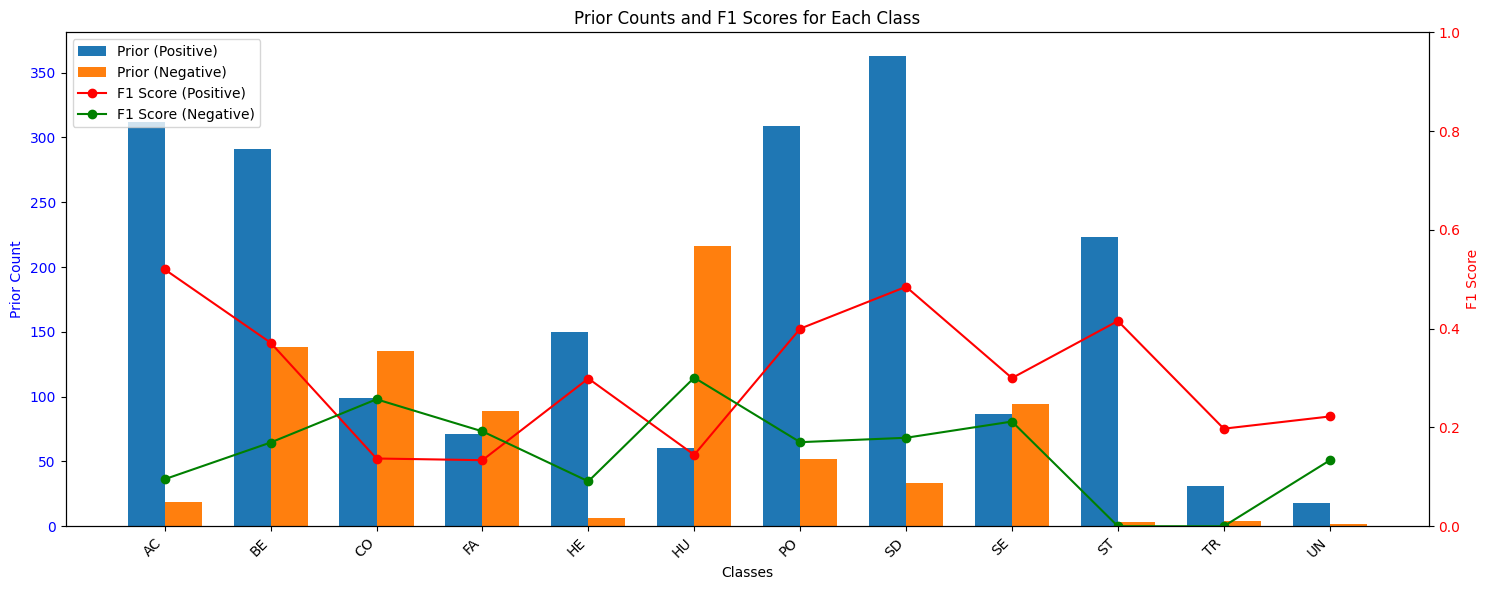

In [ ]:
# prompt: now plot 'results_df' on a graph
# x axis should be the columns (except Link1)
# y axis should have the prior count in barplot
# another y axis for the f1 scores

import matplotlib.pyplot as plt

# Create the bar plot for Prior counts
fig, ax1 = plt.subplots(figsize=(15, 6))

x_axis = results_df_reduced['Class'].unique()
bar_width = 0.35

x = np.arange(len(x_axis))

positive_prior = results_df_reduced[results_df_reduced['+\-'] == 'positive']['Prior'].values
negative_prior = results_df_reduced[results_df_reduced['+\-'] == 'negative']['Prior'].values

rects1 = ax1.bar(x - bar_width / 2, positive_prior, bar_width, label='Prior (Positive)')
rects2 = ax1.bar(x + bar_width / 2, negative_prior, bar_width, label='Prior (Negative)')

ax1.set_xlabel("Classes")
ax1.set_ylabel("Prior Count", color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_xticks(x)
ax1.set_xticklabels(x_axis, rotation=45, ha='right') # Rotate x-axis labels for readability

# Create the second y-axis for F1 scores
ax2 = ax1.twinx()
f1_scores_pos = results_df_reduced[results_df_reduced['+\-'] == 'positive']['F1 Score'].values
f1_scores_neg = results_df_reduced[results_df_reduced['+\-'] == 'negative']['F1 Score'].values

ax2.plot(x, f1_scores_pos, color='r', marker='o', label='F1 Score (Positive)')
ax2.plot(x, f1_scores_neg, color='g', marker='o', label='F1 Score (Negative)')
ax2.set_ylim(0, 1)
ax2.set_ylabel("F1 Score", color='r')
ax2.tick_params(axis='y', labelcolor='r')


# Add legends and title
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

plt.title('Prior Counts and F1 Scores for Each Class')
plt.tight_layout()  # Adjust layout to prevent overlapping labels
plt.show()

ORIGINAL 19 VALUES

In [ ]:
import pandas as pd

def compute_class_metrics(predictions: pd.DataFrame, ground_truth: pd.DataFrame) -> pd.DataFrame:
    """
    Computes TP, TN, FP, FN, and Prior counts for each class column and value (1, -1).

    Args:
        predictions (pd.DataFrame): DataFrame containing predicted values for each class column.
        ground_truth (pd.DataFrame): DataFrame containing ground truth values for each class column.

    Returns:
        pd.DataFrame: Summary table with metrics for each class column and value (1, -1).
    """
    # Identify class columns (excluding 'id')
    class_columns = list(set(predictions.columns) & set(ground_truth.columns) - {"id", "1_Link1"})
    class_columns.sort()
    results = []

    for col in class_columns:
        for value in [1, -1]:
            # True Positives
            tp = ((predictions[col] == value) & (ground_truth[col] == value)).sum()
            # True Negatives
            tn = ((predictions[col] != value) & (ground_truth[col] != value)).sum()
            # False Positives
            fp = ((predictions[col] == value) & (ground_truth[col] != value)).sum()
            # False Negatives
            fn = ((predictions[col] != value) & (ground_truth[col] == value)).sum()
            # Prior (Count in ground truth)
            prior = (ground_truth[col] == value).sum()
            # Calculate Precision
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            # Calculate Recall
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            # Calculate F1 Score
            f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

            # Append results for this class and value
            results.append({
                "Class": col,
                "+\-": value,
                "TP": tp,
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "Prior": prior,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1
            })

    # Create and return the summary DataFrame
    return pd.DataFrame(results)


In [ ]:
import pandas as pd
import numpy as np

# Assuming results_df is already defined as in your provided code

def calculate_averages(results_df):
    """Calculates weighted, micro, and macro averages of F1 score."""

    # Weighted Average
    weighted_f1 = np.average(results_df['F1 Score'], weights=results_df['Prior'])

    # Micro Average
    total_tp = results_df['TP'].sum()
    total_fp = results_df['FP'].sum()
    total_fn = results_df['FN'].sum()
    micro_precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
    micro_f1 = 2 * (micro_precision * micro_recall) / (micro_precision + micro_recall) if (micro_precision + micro_recall) > 0 else 0


    # Macro Average
    macro_f1 = np.mean(results_df['F1 Score'])

    return weighted_f1, micro_f1, macro_f1



In [ ]:
# change the names of class column by mapping dict
predictions_transformed = predictions_transformed.rename(columns=value_mappings)
ground_truth_transformed = ground_truth_transformed.rename(columns=value_mappings)

NameError: name 'predictions_transformed' is not defined

In [ ]:
results_df = compute_class_metrics(predictions_transformed, ground_truth_transformed)
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df)


print(results_df)


   Class  +\-   TP   TN   FP   FN  Prior  Precision    Recall  F1 Score
0     AC    1  182  367  208  128    312   0.466667  0.587097  0.520000
1     AC   -1    3  825   41   16     19   0.068182  0.157895  0.095238
2    BEC    1   44  601   98  142    187   0.309859  0.236559  0.268293
3    BEC   -1   10  757   18  100    112   0.357143  0.090909  0.144928
4    BED    1   34  649   94  108    142   0.265625  0.239437  0.251852
5    BED   -1    2  810   35   38     41   0.054054  0.050000  0.051948
6    COI    1    7  762   37   79     86   0.159091  0.081395  0.107692
7    COI   -1   19  701   61  104    125   0.237500  0.154472  0.187192
8    COR    1    2  834   38   11     13   0.050000  0.153846  0.075472
9    COR   -1    3  798   73   11     14   0.039474  0.214286  0.066667
10    FA    1   21  592  222   50     71   0.086420  0.295775  0.133758
11    FA   -1   17  725   71   72     89   0.193182  0.191011  0.192090
12    HE    1  115  231  504   35    150   0.185784  0.766667  0

In [ ]:
results_df = pd.read_csv('results_script_18_values_Mistral.csv')

In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df)

print("Averages for both labels")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

Averages for both labels
Weighted Average F1: 0.2474452840482346
Micro Average F1: 0.22294852340375862
Macro Average F1: 0.12433633699026247


In [ ]:
threshold = 30
filtered_df = results_df[results_df['Prior'] > threshold]
weighted_f1, micro_f1, macro_f1 = calculate_averages(filtered_df)

print("For 18 Values (both)")
print(f"Weighted Average F1 for Prior > {threshold}: {weighted_f1}")
print(f"Micro Average F1 for Prior > {threshold}: {micro_f1}")
print(f"Macro Average F1 for Prior > {threshold}: {macro_f1}")

For 18 Values (both)
Weighted Average F1 for Prior > 30: 0.257543829990458
Micro Average F1 for Prior > 30: 0.2664963814389102
Macro Average F1 for Prior > 30: 0.20792680874981107


In [ ]:
results_df_neg = results_df[results_df['+\-'] == -1]
results_df_pos = results_df[results_df['+\-'] == 1]


In [ ]:
threshold = 30
filtered_df = results_df_pos[results_df_pos['Prior'] > threshold]
weighted_f1, micro_f1, macro_f1 = calculate_averages(filtered_df)

print(f"Weighted Average F1 for Prior > {threshold}: {weighted_f1}")
print(f"Micro Average F1 for Prior > {threshold}: {micro_f1}")
print(f"Macro Average F1 for Prior > {threshold}: {macro_f1}")

Weighted Average F1 for Prior > 30: 0.28617412226020256
Micro Average F1 for Prior > 30: 0.29632366525032333
Macro Average F1 for Prior > 30: 0.23369485148925978


In [ ]:
threshold = 30
filtered_df = results_df_neg[results_df_neg['Prior'] > threshold]
weighted_f1, micro_f1, macro_f1 = calculate_averages(filtered_df)
results_df_neg
print(f"Weighted Average F1 for Prior > {threshold}: {weighted_f1}")
print(f"Micro Average F1 for Prior > {threshold}: {micro_f1}")
print(f"Macro Average F1 for Prior > {threshold}: {macro_f1}")

Weighted Average F1 for Prior > 30: 0.17273409708511675
Micro Average F1 for Prior > 30: 0.16768665850673195
Macro Average F1 for Prior > 30: 0.15639072327091366


In [ ]:
filtered_df


,Class,+\-,TP,TN,FP,FN,Prior,Precision,Recall,F1 Score
3,BEC,-1,16,685,88,93,112,0.153846,0.146789,0.150235
5,BED,-1,6,754,88,34,41,0.063830,0.150000,0.089552
7,COI,-1,21,646,114,101,125,0.155556,0.172131,0.163424
11,FA,-1,24,666,127,65,89,0.158940,0.269663,0.200000
15,HU,-1,37,543,124,178,216,0.229814,0.172093,0.196809
17,POD,-1,7,721,117,37,44,0.056452,0.159091,0.083333
25,SEP,-1,26,662,133,61,88,0.163522,0.298851,0.211382


In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_pos)

print("For 18 Values (positive)")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

For 18 Values (positive)
Weighted Average F1: 0.2820922725556541
Micro Average F1: 0.28470380194518125
Macro Average F1: 0.17879541913262834


In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_neg)

print("For 18 Values (negative)")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

For 18 Values (negative)
Weighted Average F1: 0.15622659092772123
Micro Average F1: 0.10302197802197802
Macro Average F1: 0.06987725484789664


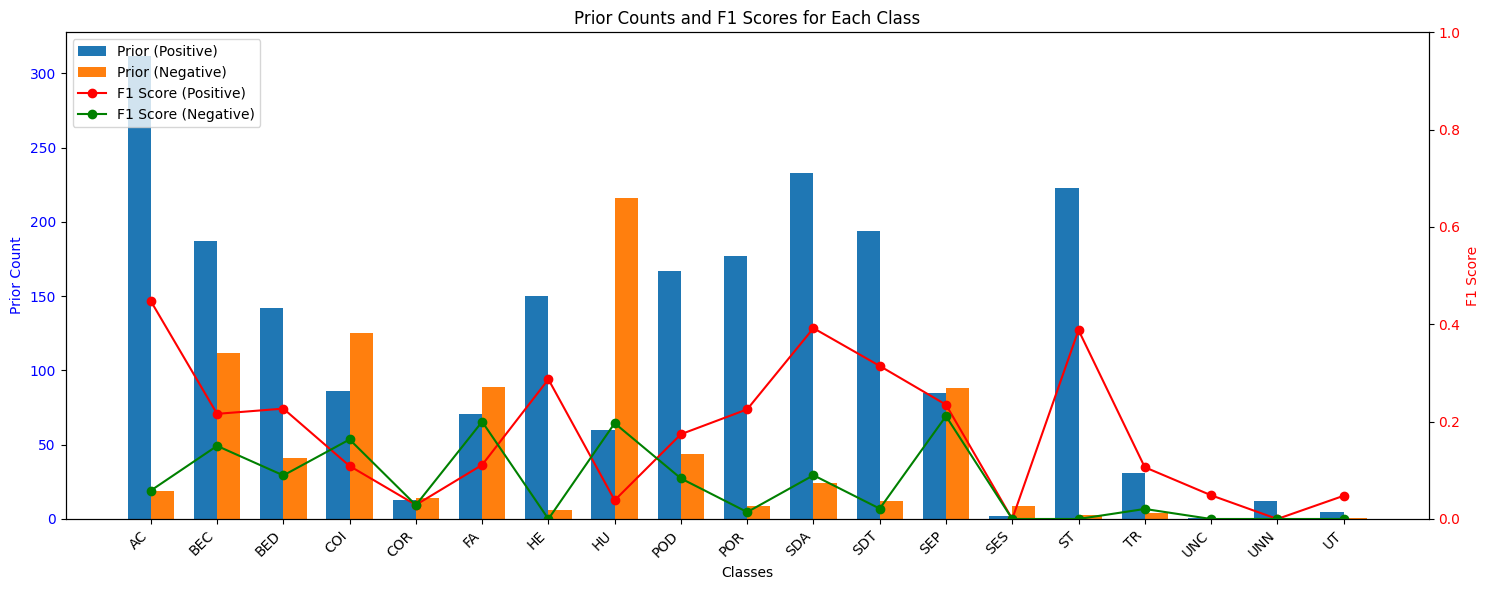

In [ ]:
# prompt: now plot 'results_df' on a graph
# x axis should be the columns (except Link1)
# y axis should have the prior count in barplot
# another y axis for the f1 scores

import matplotlib.pyplot as plt

# Create the bar plot for Prior counts
fig, ax1 = plt.subplots(figsize=(15, 6))

x_axis = results_df['Class'].unique()
bar_width = 0.35

x = np.arange(len(x_axis))

positive_prior = results_df[results_df['+\-'] == 1]['Prior'].values
negative_prior = results_df[results_df['+\-'] == -1]['Prior'].values

rects1 = ax1.bar(x - bar_width / 2, positive_prior, bar_width, label='Prior (Positive)')
rects2 = ax1.bar(x + bar_width / 2, negative_prior, bar_width, label='Prior (Negative)')

ax1.set_xlabel("Classes")
ax1.set_ylabel("Prior Count", color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_xticks(x)
ax1.set_xticklabels(x_axis, rotation=45, ha='right') # Rotate x-axis labels for readability

# Create the second y-axis for F1 scores
ax2 = ax1.twinx()
f1_scores_pos = results_df[results_df['+\-'] == 1]['F1 Score'].values
f1_scores_neg = results_df[results_df['+\-'] == -1]['F1 Score'].values

ax2.plot(x, f1_scores_pos, color='r', marker='o', label='F1 Score (Positive)')
ax2.plot(x, f1_scores_neg, color='g', marker='o', label='F1 Score (Negative)')
ax2.set_ylim(0, 1)
ax2.set_ylabel("F1 Score", color='r')
ax2.tick_params(axis='y', labelcolor='r')


# Add legends and title
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

plt.title('Prior Counts and F1 Scores for Each Class')
plt.tight_layout()  # Adjust layout to prevent overlapping labels
plt.show()

In [ ]:
results_df.to_csv('script2val_results_df_RERUN.csv', index=False)

In [ ]:
results_df = pd.read_csv('script2val_results_df_RERUN.csv')

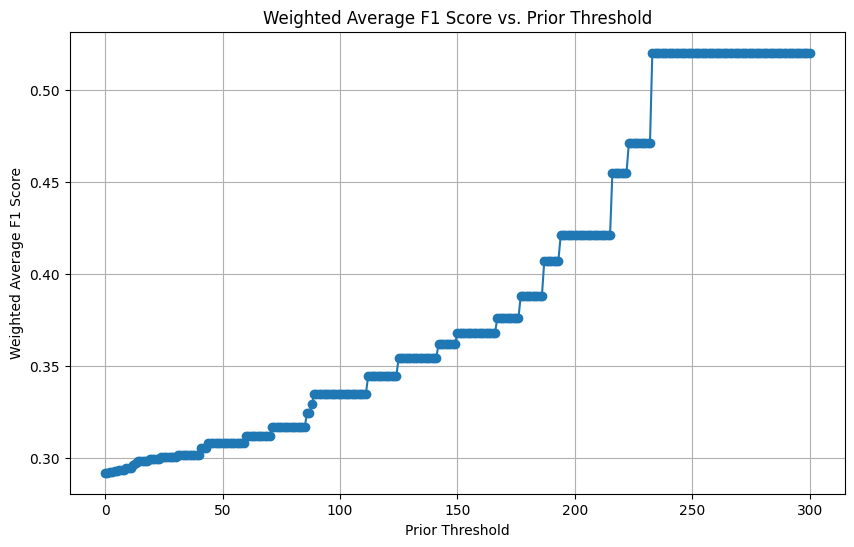

In [ ]:
# prompt: plot for X the treshold for prior and for y the Weighted Average F1 for all treshold from 0 to 300

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

weighted_f1_scores = []
thresholds = list(range(0, 301))  # Thresholds from 0 to 300

for threshold in thresholds:
    filtered_df = results_df[results_df['Prior'] > threshold]
    weighted_f1, _, _ = calculate_averages(filtered_df)
    weighted_f1_scores.append(weighted_f1)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, weighted_f1_scores, marker='o', linestyle='-')
plt.title('Weighted Average F1 Score vs. Prior Threshold')
plt.xlabel('Prior Threshold')
plt.ylabel('Weighted Average F1 Score')
plt.grid(True)
plt.show()